# TD4 — Corrigé

Graphiques et simulation simple à partir d’OWID

Les dix valeurs sont celles de l’énoncé. World est un agrégat déjà inclus avec neuf pays : leur moyenne simple n’est donc pas le taux mondial. Dans le parcours obligatoire, les tirages restent aléatoires ; les résultats affichés correspondent à une exécution, pas à des valeurs à retrouver exactement.

Exécuter toutes les cellules dans l’ordre, depuis une session neuve. Pour les données, extraire le dossier complet et ouvrir le notebook à sa racine. Les sorties sont celles d’une exécution de référence.

Bibliothèques : matplotlib ; pandas en plus au TD5.

In [1]:
# Afficher les figures dans le notebook.
%matplotlib inline

## Démarche en pseudo-code 1 — Visualiser puis simuler

```text
# Objectif : observer une distribution puis simuler des tirages
# Entree : liste de taux de fecondite
# 1. Calculer la moyenne observee
# 2. Tracer un graphique en barres
# 3. Tirer au hasard une valeur dans la liste
# 4. Repeter le tirage plusieurs fois
# 5. Calculer la moyenne des tirages
# 6. Observer si la moyenne se stabilise quand n augmente
```

Les exercices qui suivent mettent en œuvre ce plan, étape par étape.

## Démarche en pseudo-code 2 — Passer des tirages à une courbe

```text
# Objectif : voir si la moyenne simulee se stabilise
# Entree : plusieurs tailles de simulation
# 1. Creer une liste vide pour les moyennes
# 2. Pour chaque taille n :
#       faire n tirages
#       calculer la moyenne des tirages
#       ajouter cette moyenne a la liste
# 3. Tracer tailles en abscisse et moyennes en ordonnee
# Sortie : graphique de stabilisation
```

Les exercices qui suivent mettent en œuvre ce plan, étape par étape.

## Exercice 1 — Créer l'extrait OWID

**Objectif.** Créer l’extrait et calculer sa moyenne simple.

**Démarche.** Les valeurs du dictionnaire deviennent une liste ; leur moyenne servira de référence dans la simulation.

In [2]:
fertilite = {
    "World": 2.3,
    "France": 1.8,
    "United States": 1.6,
    "Japan": 1.2,
    "India": 2.0,
    "Nigeria": 4.5,
    "Niger": 6.1,
    "Brazil": 1.6,
    "Ethiopia": 3.9,
    "China": 1.0
}
valeurs = list(fertilite.values())
moyenne_initiale = sum(valeurs) / len(valeurs)
print("Nombre d'observations :", len(valeurs))
print(f"Moyenne simple : {moyenne_initiale:.2f} enfants par femme")


Nombre d'observations : 10
Moyenne simple : 2.60 enfants par femme


**Résultat et interprétation.** 10 observations ; 2.60 enfants par femme. La référence World de l’extrait vaut 2.3 : ce sont deux calculs différents.

## Exercice 2 — Observer clés et valeurs

**Objectif.** Observer les listes de clés et de valeurs.

**Démarche.** keys et values suivent le même ordre d’insertion. La tranche [:3] conserve les trois premiers éléments.

In [3]:
pays = list(fertilite.keys())
valeurs = list(fertilite.values())
print(pays[:3])
print(valeurs[:3])
print(len(pays) == len(valeurs))
# Chaque barre doit avoir à la fois une étiquette et une hauteur.


['World', 'France', 'United States']
[2.3, 1.8, 1.6]
True


**Résultat et interprétation.** ['World', 'France', 'United States'] ; [2.3, 1.8, 1.6] ; True.

## Exercice 3 — Graphique en barres

**Objectif.** Tracer les taux de fécondité.

**Démarche.** Utiliser les noms sur l’axe horizontal et les valeurs sur l’axe vertical. Garder le zéro comme origine des barres.

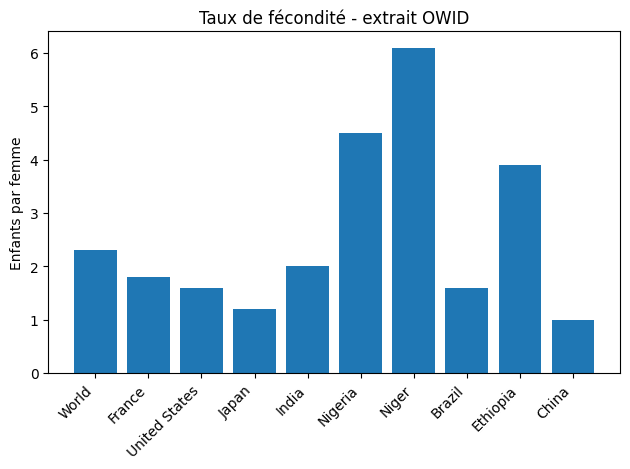

In [4]:
import matplotlib.pyplot as plt

plt.figure()
plt.bar(pays, valeurs)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Enfants par femme")
plt.title("Taux de fécondité - extrait OWID")
plt.tight_layout()
plt.savefig("fertilite_barres.png", dpi=300)
plt.show()
plt.close()


**Résultat et interprétation.** Une figure de dix barres : Niger est la plus haute, China la plus basse. World est une référence agrégée.

## Exercice 4 — Modifier un paramètre graphique

**Objectif.** Modifier le titre et le nom de fichier.

**Démarche.** Reprendre les mêmes données et les mêmes paramètres graphiques ; changer seulement ces deux éléments.

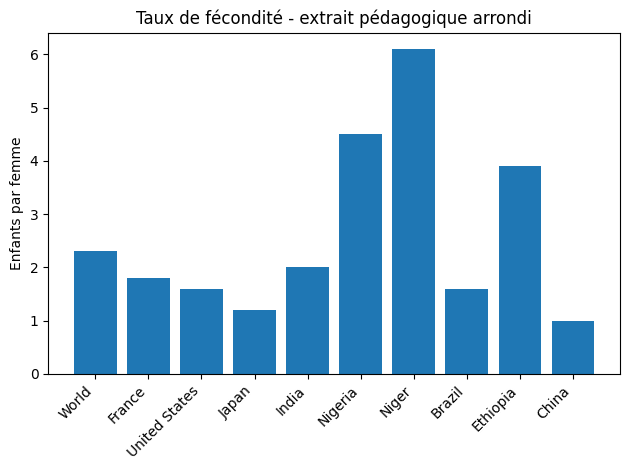

In [5]:
plt.figure()
plt.bar(pays, valeurs)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Enfants par femme")
plt.title("Taux de fécondité - extrait pédagogique arrondi")
plt.tight_layout()
plt.savefig("fertilite_barres_version2.png", dpi=300)
plt.show()
plt.close()


**Résultat et interprétation.** Les deux fichiers fertilite_barres.png et fertilite_barres_version2.png existent avec les mêmes hauteurs de barres.

## Exercice 5 — Interpréter le graphique

**Objectif.** Interpréter les extrêmes et la lisibilité.

**Démarche.** Lire les deux barres extrêmes puis expliquer ce que la représentation facilite.

In [6]:
# Niger a le taux le plus élevé dans l'extrait : 6,1 enfants par femme.
# China a le taux le plus faible : 1,0 enfant par femme.
# Les hauteurs des barres facilitent la comparaison des niveaux et des écarts,
# à condition de conserver des axes et des unités lisibles.


**Résultat et interprétation.** Les conclusions portent sur cet extrait arrondi, pas sur l’ensemble des pays.

## Exercice 6 — Un tirage aléatoire

**Objectif.** Tirer une valeur au hasard.

**Démarche.** random fait partie de Python. choice choisit un élément de la liste ; les valeurs peuvent être tirées à nouveau lors des appels suivants.

In [7]:
import random

tirage = random.choice(valeurs)
print("Un tirage :", tirage)


Un tirage : 1.6


**Résultat et interprétation.** La valeur appartient à la liste et peut changer à chaque exécution. Deux exécutions peuvent aussi donner le même résultat.

**Point de vigilance.** Les dix positions ont le même poids. La valeur 1.6 apparaît deux fois et a donc deux chances sur dix d’être tirée.

## Exercice 7 — Prédire le rôle de range

**Objectif.** Comprendre le nombre de répétitions avec range.

**Démarche.** range(3) fournit 0, 1 et 2 ; la borne finale 3 est exclue.

In [8]:
for i in range(3):
    print(i)
for i in range(1):
    print("tirage")
# range(20) fournit vingt entiers, de 0 à 19 : vingt tours de boucle.


0
1
2
tirage


**Résultat et interprétation.** Trois lignes (0, 1, 2), puis une ligne tirage.

## Exercice 8 — Moyenne de plusieurs tirages

**Objectif.** Calculer la moyenne de vingt tirages et corriger une boucle.

**Démarche.** Ajouter une valeur à la liste à chaque tour puis calculer la moyenne hors de la boucle.

In [9]:
tirages = []
for i in range(20):
    tirages.append(random.choice(valeurs))
moyenne_tirages = sum(tirages) / len(tirages)
print("Nombre de tirages :", len(tirages))
print(f"Moyenne des tirages : {moyenne_tirages:.3f}")
print(f"Référence de la liste : {moyenne_initiale:.3f}")
# Sans : à la fin de for, Python signale SyntaxError.
# Sans indentation du corps de for, Python signale IndentationError.


Nombre de tirages : 20
Moyenne des tirages : 2.490
Référence de la liste : 2.600


**Résultat et interprétation.** 20 tirages ; leur moyenne fluctue autour de 2.60 et peut être au-dessus ou au-dessous. Les deux-points et l’indentation sont obligatoires.

## Exercice 9 — Stabilisation de la moyenne

**Objectif.** Comparer quatre tailles de simulation.

**Démarche.** La liste tirages doit être remise à zéro pour chaque taille. Les simulations sont distinctes, et non les préfixes d’un seul tirage de 1000 valeurs.

In [10]:
tailles = [5, 20, 100, 1000]
for n in tailles:
    tirages = []
    for i in range(n):
        tirages.append(random.choice(valeurs))
    print(f"Pour {n} tirages : moyenne {sum(tirages) / len(tirages):.3f}")


Pour 5 tirages : moyenne 2.760
Pour 20 tirages : moyenne 2.665
Pour 100 tirages : moyenne 2.450
Pour 1000 tirages : moyenne 2.598


**Résultat et interprétation.** Quatre moyennes simulées, généralement plus proches de 2.60 aux grandes tailles. La distance ne diminue pas nécessairement à chaque étape.

## Exercice 10 — Graphique de stabilisation

**Objectif.** Tracer les moyennes simulées et leur référence.

**Démarche.** Conserver une moyenne par taille dans une deuxième liste. La ligne horizontale représente la moyenne connue de la liste de départ.

Moyennes représentées : [2.7600000000000002, 2.9, 2.6609999999999996, 2.5806]


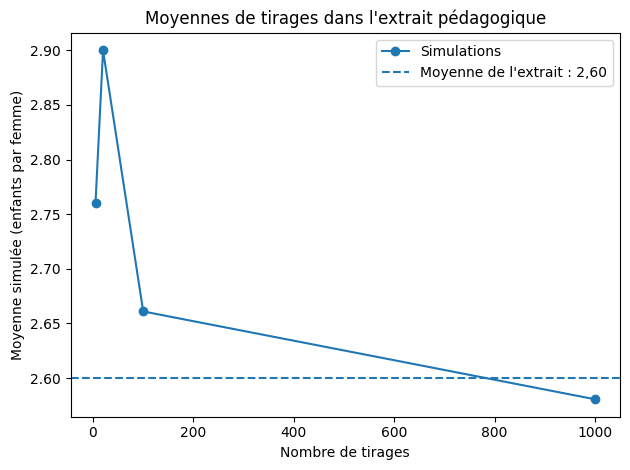

In [11]:
tailles = [5, 20, 100, 1000]
moyennes_simulees = []
for n in tailles:
    tirages = []
    for i in range(n):
        tirages.append(random.choice(valeurs))
    moyenne_n = sum(tirages) / len(tirages)
    moyennes_simulees.append(moyenne_n)
print("Moyennes représentées :", moyennes_simulees)

plt.figure()
plt.plot(tailles, moyennes_simulees, marker="o", label="Simulations")
plt.axhline(moyenne_initiale, linestyle="--", label="Moyenne de l'extrait : 2,60")
plt.xlabel("Nombre de tirages")
plt.ylabel("Moyenne simulée (enfants par femme)")
plt.title("Moyennes de tirages dans l'extrait pédagogique")
plt.legend()
plt.tight_layout()
plt.savefig("simulation_moyenne.png", dpi=300)
plt.show()
plt.close()


**Résultat et interprétation.** Quatre points et une ligne de référence à 2.60. Cette figure utilise de nouveaux tirages : les moyennes peuvent différer de celles de l’exercice 9.

## Exercice 11 — Interprétation économique

**Objectif.** Distinguer simulation et interprétation économique.

**Démarche.** La simulation reproduit la liste choisie avec le même poids pour chaque position ; elle ne crée pas de nouvelles observations sur la population mondiale.

In [12]:
# La moyenne de 2,60 résume les dix valeurs sélectionnées, sans pondération.
# Avec davantage de tirages indépendants, la moyenne fluctue généralement moins
# autour de la moyenne de cette liste, sans rapprochement nécessaire à chaque étape.
# Cette liste mêle un agrégat World et neuf pays, sans poids démographiques :
# la simulation ne mesure donc pas directement le taux mondial de fécondité.
# Changer les pays ou leurs poids change la distribution de départ et sa moyenne.


**Résultat et interprétation.** La stabilisation concerne ce mécanisme de tirage dans une liste, et non une tendance démographique observée.

## Question facultative 1 — Fixer et répéter une graine.

**Objectif.** Fixer et répéter une graine.

**Démarche.** Replacer la même graine avant deux séries identiques reproduit la même suite dans le même environnement Python. Un seul seed au début n’oblige pas tous les tirages à être identiques.

In [13]:
random.seed(123)
serie_a = []
for i in range(5):
    serie_a.append(random.choice(valeurs))
random.seed(123)
serie_b = []
for i in range(5):
    serie_b.append(random.choice(valeurs))
print(serie_a)
print(serie_b)
print("Séries identiques :", serie_a == serie_b)


[2.3, 2.0, 1.8, 6.1, 2.0]
[2.3, 2.0, 1.8, 6.1, 2.0]
Séries identiques : True


**Résultat et interprétation.** True. La graine est introduite ici, comme dans la progression de l’énoncé.

## Question facultative 2 — Comparer dix moyennes de vingt tirages.

**Objectif.** Comparer dix moyennes de vingt tirages.

**Démarche.** La boucle extérieure représente les simulations ; la boucle intérieure représente les tirages d’une simulation.

In [14]:
moyennes_20 = []
for simulation in range(10):
    tirages_20 = []
    for i in range(20):
        tirages_20.append(random.choice(valeurs))
    moyennes_20.append(sum(tirages_20) / len(tirages_20))
print(moyennes_20)


[3.275, 2.43, 3.11, 2.9, 2.5949999999999998, 3.3, 3.2449999999999997, 3.225, 3.1100000000000003, 2.46]


**Résultat et interprétation.** Dix moyennes qui varient autour de 2.60 ; elles ne doivent pas nécessairement être toutes différentes.

## Question facultative 3 — Tracer un histogramme de mille tirages.

**Objectif.** Tracer un histogramme de mille tirages.

**Démarche.** Conserver les mille valeurs pour représenter leur distribution, puis compter les observations par classe avec hist.

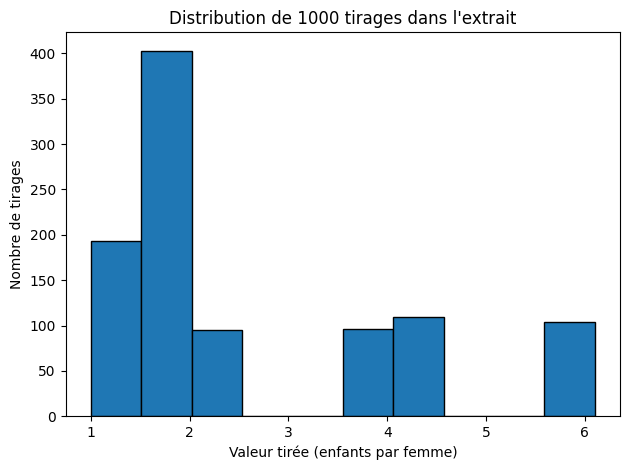

In [15]:
tirages_1000 = []
for i in range(1000):
    tirages_1000.append(random.choice(valeurs))
plt.figure()
plt.hist(tirages_1000, bins=10, edgecolor="black")
plt.xlabel("Valeur tirée (enfants par femme)")
plt.ylabel("Nombre de tirages")
plt.title("Distribution de 1000 tirages dans l'extrait")
plt.tight_layout()
plt.savefig("histogramme_tirages.png", dpi=300)
plt.show()
plt.close()


**Résultat et interprétation.** L’histogramme reflète les valeurs possibles de la liste. Les classes regroupent les tirages ; il ne décrit pas la distribution réelle des populations.

## Question facultative 4 — Recalculer la moyenne sans Niger.

**Objectif.** Recalculer la moyenne sans Niger.

**Démarche.** Créer une nouvelle liste en excluant la clé Niger ; préserver les données de la simulation initiale.

In [16]:
valeurs_sans_niger = []
for pays_test in fertilite:
    if pays_test != "Niger":
        valeurs_sans_niger.append(fertilite[pays_test])
moyenne_sans_niger = sum(valeurs_sans_niger) / len(valeurs_sans_niger)
print(f"Sans Niger : {moyenne_sans_niger:.3f} enfants par femme")


Sans Niger : 2.211 enfants par femme


**Résultat et interprétation.** 19.9/9 = 2.211… au lieu de 2.600. Retirer une grande valeur abaisse la moyenne.

## Question facultative 5 — Ajouter la médiane à la figure de simulation.

**Objectif.** Ajouter la médiane à la figure de simulation.

**Démarche.** Trier les dix valeurs et faire la moyenne des deux valeurs centrales aux indices 4 et 5.

Médiane de l'extrait : 1.9


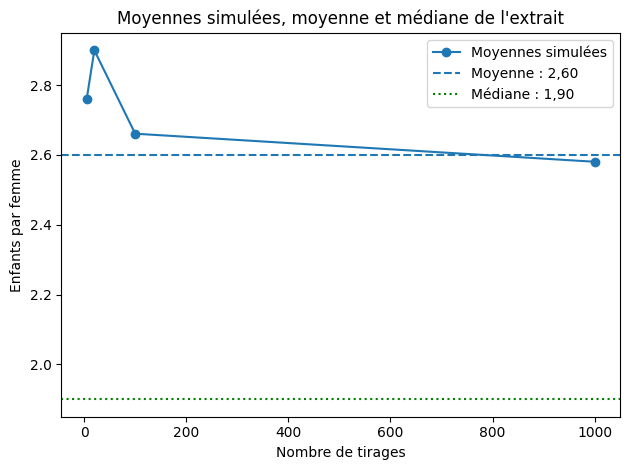

In [17]:
valeurs_triees = sorted(valeurs)
mediane_initiale = (valeurs_triees[4] + valeurs_triees[5]) / 2
print("Médiane de l'extrait :", mediane_initiale)
plt.figure()
plt.plot(tailles, moyennes_simulees, marker="o", label="Moyennes simulées")
plt.axhline(moyenne_initiale, linestyle="--", label="Moyenne : 2,60")
plt.axhline(mediane_initiale, color="green", linestyle=":", label="Médiane : 1,90")
plt.xlabel("Nombre de tirages")
plt.ylabel("Enfants par femme")
plt.title("Moyennes simulées, moyenne et médiane de l'extrait")
plt.legend()
plt.tight_layout()
plt.savefig("simulation_mediane.png", dpi=300)
plt.show()
plt.close()


**Résultat et interprétation.** Médiane 1.9. La moyenne simulée tend vers la moyenne 2.6, pas vers la médiane : la ligne verte est une autre statistique de référence.

## Question facultative 6 — Créer une fonction moyenne_tirages(n).

**Objectif.** Créer une fonction moyenne_tirages(n).

**Démarche.** Initialiser la liste à l’intérieur de la fonction pour que chaque appel crée une nouvelle simulation. n doit être un entier strictement positif.

In [18]:
def moyenne_tirages(n):
    valeurs_tirees = []
    for i in range(n):
        valeurs_tirees.append(random.choice(valeurs))
    return sum(valeurs_tirees) / len(valeurs_tirees)

print("Moyenne de 20 tirages :", moyenne_tirages(20))


Moyenne de 20 tirages : 2.1399999999999997


**Résultat et interprétation.** Une moyenne aléatoire de vingt valeurs ; n = 0 provoquerait une division par zéro.

## Question facultative 7 — Tester de nouvelles tailles.

**Objectif.** Tester de nouvelles tailles.

**Démarche.** Réutiliser la fonction précédente sans changer le mécanisme de tirage.

In [19]:
tailles_extension = [10, 50, 500, 5000]
moyennes_extension = []
for n in tailles_extension:
    moyenne_n = moyenne_tirages(n)
    moyennes_extension.append(moyenne_n)
    print(n, moyenne_n)


10 2.66
50 2.7539999999999996
500 2.5008000000000004
5000 2.5528


**Résultat et interprétation.** Quatre nouvelles moyennes. Les grandes tailles réduisent généralement les fluctuations.

## Question facultative 8 — Mesurer la distance à la moyenne initiale.

**Objectif.** Mesurer la distance à la moyenne initiale.

**Démarche.** L’écart signé indique le côté de la référence ; abs donne une distance positive. Reprendre les simulations conservées, sans effectuer un nouveau tirage.

In [20]:
for i in range(len(tailles_extension)):
    ecart = moyennes_extension[i] - moyenne_initiale
    print(f"n={tailles_extension[i]} : écart {ecart:.4f}, distance {abs(ecart):.4f}")


n=10 : écart 0.0600, distance 0.0600
n=50 : écart 0.1540, distance 0.1540
n=500 : écart -0.0992, distance 0.0992
n=5000 : écart -0.0472, distance 0.0472


**Résultat et interprétation.** Un écart positif signifie une moyenne simulée supérieure à 2.60 ; un écart négatif signifie l’inverse.

## Question facultative 9 — Expliquer intuitivement la stabilisation.

**Objectif.** Expliquer intuitivement la stabilisation.

**Démarche.** Les écarts des tirages se compensent davantage lorsqu’ils sont nombreux.

In [21]:
# Stabiliser signifie que la moyenne des tirages se concentre davantage
# autour de la moyenne de la liste quand le nombre de tirages augmente.
# Cela ne garantit ni l'égalité exacte, ni une distance décroissante à chaque n.


**Résultat et interprétation.** La loi des grands nombres concerne des répétitions selon le même mécanisme ; elle ne corrige pas une sélection de pays non représentative.

## Question facultative 10 — Construire l’intervalle avancé demandé.

**Objectif.** Construire l’intervalle avancé demandé.

**Démarche.** L’énoncé donne la forme moyenne ± 2 × écart-type / racine(n), sans préciser l’écart-type. On utilise ici celui de la distribution de tirage connue : dix positions équiprobables, division par 10. L’intervalle est une approximation pour la moyenne de ce mécanisme.

In [22]:
somme_carres = 0
for valeur in valeurs:
    somme_carres = somme_carres + (valeur - moyenne_initiale) ** 2
ecart_type = (somme_carres / len(valeurs)) ** 0.5
n_intervalle = len(tirages_1000)
moyenne_intervalle = sum(tirages_1000) / n_intervalle
marge = 2 * ecart_type / n_intervalle ** 0.5
borne_basse = moyenne_intervalle - marge
borne_haute = moyenne_intervalle + marge
print(f"Intervalle approximatif : [{borne_basse:.3f} ; {borne_haute:.3f}]")
print(f"Marge : {marge:.3f} enfants par femme")


Intervalle approximatif : [2.531 ; 2.732]
Marge : 0.100 enfants par femme


**Résultat et interprétation.** Pour 1000 tirages, la marge vaut environ 0.100. Sous l’approximation normale, le facteur 2 correspond à une couverture proche de 95 %, sans garantie pour chaque simulation. Ce n’est pas un intervalle pour le taux mondial.